# Fraud Detection with AI, Machine Learning & Deep Learning

A complete, end-to-end walkthrough of building fraud-detection models on real
transaction data — spanning classical ML, ensemble methods, an unsupervised
"AI" anomaly detector, and two deep-learning approaches (a supervised MLP and
an unsupervised autoencoder) — with rigorous evaluation for a **highly
imbalanced classification problem**.

## Dataset

We use **`fraud_data.csv`**, a ~21.7k-row subset of the well-known
**"Credit Card Fraud Detection"** dataset originally released by the
Machine Learning Group of Université Libre de Bruxelles (ULB) / Worldline,
and popularized as a teaching dataset (University of Michigan, "Applied
Machine Learning in Python", Coursera). It is small (~11 MB, freely hosted
on GitHub) which makes it ideal for a full notebook run without needing a
Kaggle account or a multi-hundred-MB download.

- **Rows:** 21,693 transactions
- **Features:** `V1`–`V28` (anonymized PCA components of the original
  transaction features, for confidentiality) + `Amount`
- **Target:** `Class` (`1` = fraud, `0` = legitimate)
- **Class imbalance:** only ~1.6% of transactions are fraudulent — this is
  the central challenge of the whole notebook.

## What this notebook covers

1. Data acquisition & exploratory data analysis (EDA)
2. Preprocessing, scaling, and imbalance handling (SMOTE)
3. **Classical ML:** Logistic Regression, Random Forest, XGBoost
4. **Unsupervised "AI" anomaly detection:** Isolation Forest
5. **Deep Learning:** a supervised feed-forward neural network (Keras/TensorFlow)
6. **Deep Learning (unsupervised):** an autoencoder-based anomaly detector
7. Rigorous evaluation: accuracy, precision, recall, F1, ROC-AUC, PR-AUC,
   confusion matrices, ROC & Precision-Recall curves
8. Feature importance
9. Decision-threshold tuning for a cost-sensitive business setting
10. Conclusions & next steps

> **Note on metric choice:** with ~1.6% fraud prevalence, accuracy is almost
> meaningless (predicting "not fraud" for everyone gives ~98.4% accuracy).
> We treat **Precision-Recall AUC, Recall, and F1** as the primary metrics
> throughout, and only report accuracy/ROC-AUC as supporting context.


## 0. Setup — install & import libraries

In [1]:

import sys, subprocess

def _ensure(pkg, import_name=None):
    import importlib
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

for pkg, imp in [("tensorflow-cpu", "tensorflow"),
                  ("xgboost", "xgboost"),
                  ("imbalanced-learn", "imblearn")]:
    _ensure(pkg, imp)
print("All dependencies available.")


I0000 00:00:1788705378.463294     596 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788705378.504804     596 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788705379.886075     596 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


All dependencies available.


In [2]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

from imblearn.over_sampling import SMOTE
import xgboost as xgb

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

print("TensorFlow:", tf.__version__)
print("XGBoost:", xgb.__version__)


TensorFlow: 2.21.0
XGBoost: 3.4.1


## 1. Data Acquisition

The dataset is fetched from its public GitHub mirror. If you already have
`fraud_data.csv` locally, place it in the working directory and the download
step will be skipped.

In [3]:

import os, urllib.request

DATA_URL = "https://raw.githubusercontent.com/sidsriv/Applied-ML-in-Python/master/fraud_data.csv"
DATA_PATH = "fraud_data.csv"

if not os.path.exists(DATA_PATH):
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Download complete.")
else:
    print("Dataset already present locally.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Dataset already present locally.


Shape: (21693, 30)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,1.176563,0.323798,0.536927,1.047002,-0.368652,-0.728586,0.084678,-0.069246,-0.266389,0.155315,...,-0.109627,-0.341365,0.057845,0.499180,0.415211,-0.581949,0.015472,0.018065,4.67,0
1,0.681109,-3.934776,-3.801827,-1.147468,-0.735540,-0.501097,1.038865,-0.626979,-2.274423,1.527782,...,0.652202,0.272684,-0.982151,0.165900,0.360251,0.195321,-0.256273,0.056501,912.00,0
2,1.140729,0.453484,0.247010,2.383132,0.343287,0.432804,0.093380,0.173310,-0.808999,0.775436,...,-0.003802,0.058556,-0.121177,-0.304215,0.645893,0.122600,-0.012115,-0.005945,1.00,0
3,-1.107073,-3.298902,-0.184092,-1.795744,2.137564,-1.684992,-2.015606,-0.007181,-0.165760,0.869659,...,0.130648,0.329445,0.927656,-0.049560,-1.892866,-0.575431,0.266573,0.414184,62.10,0
4,-0.314818,0.866839,-0.124577,-0.627638,2.651762,3.428128,0.194637,0.670674,-0.442658,0.133499,...,-0.312774,-0.799494,-0.064488,0.953062,-0.429550,0.158225,0.076943,-0.015051,2.67,0


## 2. Exploratory Data Analysis (EDA)

In [4]:

print(df.info())
print("\nMissing values per column:\n", df.isna().sum().sum(), "total missing values")
print("\nSummary statistics:")
df.describe().T


<class 'pandas.DataFrame'>
RangeIndex: 21693 entries, 0 to 21692
Data columns (total 30 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      21693 non-null  float64
 1   V2      21693 non-null  float64
 2   V3      21693 non-null  float64
 3   V4      21693 non-null  float64
 4   V5      21693 non-null  float64
 5   V6      21693 non-null  float64
 6   V7      21693 non-null  float64
 7   V8      21693 non-null  float64
 8   V9      21693 non-null  float64
 9   V10     21693 non-null  float64
 10  V11     21693 non-null  float64
 11  V12     21693 non-null  float64
 12  V13     21693 non-null  float64
 13  V14     21693 non-null  float64
 14  V15     21693 non-null  float64
 15  V16     21693 non-null  float64
 16  V17     21693 non-null  float64
 17  V18     21693 non-null  float64
 18  V19     21693 non-null  float64
 19  V20     21693 non-null  float64
 20  V21     21693 non-null  float64
 21  V22     21693 non-null  float64
 22  V23     2

,count,mean,std,min,25%,50%,75%,max
V1,21693.0,-0.032403,2.106997,-41.928738,-0.929371,0.007545,1.315678,2.451888
V2,21693.0,0.047565,1.690911,-40.803981,-0.592921,0.075215,0.819749,21.467203
V3,21693.0,-0.091623,1.870289,-31.103685,-0.962975,0.176534,1.020809,4.069865
V4,21693.0,0.057805,1.540329,-4.848504,-0.850069,-0.012868,0.772388,12.114672
V5,21693.0,-0.033983,1.530508,-32.092129,-0.698296,-0.063948,0.615287,29.162172
V6,21693.0,-0.023207,1.340599,-20.367836,-0.779041,-0.281565,0.383633,21.393069
V7,21693.0,-0.074203,1.596775,-41.506796,-0.565297,0.030859,0.563751,34.303177
V8,21693.0,0.002096,1.412650,-38.987263,-0.205943,0.023159,0.328411,20.007208
V9,21693.0,-0.044311,1.158554,-13.434066,-0.669752,-0.073996,0.590212,9.125535
V10,21693.0,-0.091073,1.354886,-24.403185,-0.554596,-0.099291,0.445474,12.701539


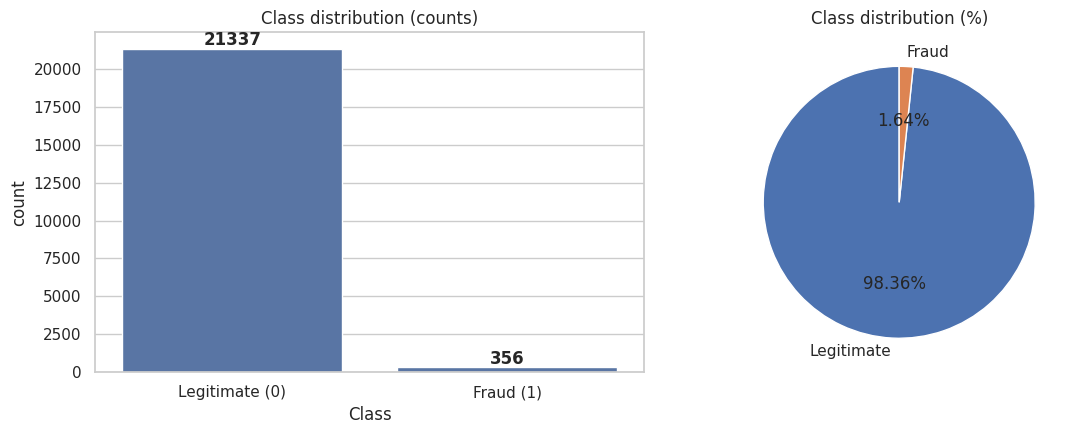

Fraud rate: 1.641% of all transactions


In [5]:
# Check for imbalance data as fraud are much lesser than legitamate
class_counts = df["Class"].value_counts()
class_pct = df["Class"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(x="Class", data=df, ax=ax[0])
ax[0].set_title("Class distribution (counts)")
ax[0].set_xticklabels(["Legitimate (0)", "Fraud (1)"])
for i, v in enumerate(class_counts.sort_index()):
    ax[0].text(i, v + 200, str(v), ha="center", fontweight="bold")

ax[1].pie(class_counts, labels=["Legitimate", "Fraud"], autopct="%1.2f%%",
          colors=sns.color_palette("deep")[:2], startangle=90)
ax[1].set_title("Class distribution (%)")
plt.tight_layout()
plt.show()

print(f"Fraud rate: {class_pct[1]:.3f}% of all transactions")


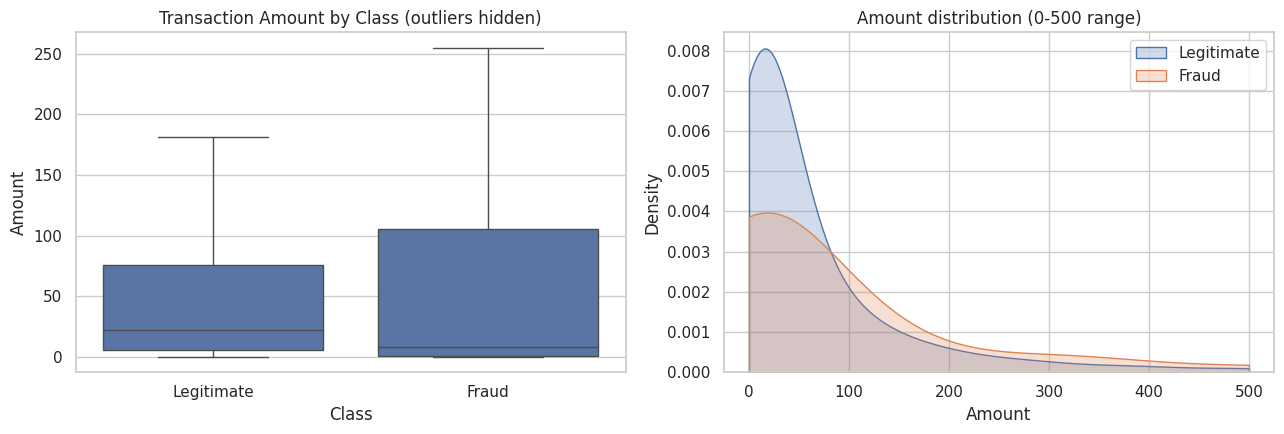

         count        mean         std  min   25%    50%     75%      max
Class                                                                    
0      21337.0   86.285312  235.704608  0.0  5.53  21.99   75.98  7712.43
1        356.0  116.200618  230.431421  0.0  1.00   8.15  105.08  1402.16


In [6]:

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(x="Class", y="Amount", data=df, ax=ax[0], showfliers=False)
ax[0].set_title("Transaction Amount by Class (outliers hidden)")
ax[0].set_xticklabels(["Legitimate", "Fraud"])

sns.kdeplot(df.loc[df.Class == 0, "Amount"], label="Legitimate", ax=ax[1], fill=True, clip=(0, 500))
sns.kdeplot(df.loc[df.Class == 1, "Amount"], label="Fraud", ax=ax[1], fill=True, clip=(0, 500))
ax[1].set_title("Amount distribution (0-500 range)")
ax[1].legend()
plt.tight_layout()
plt.show()

print(df.groupby("Class")["Amount"].describe())


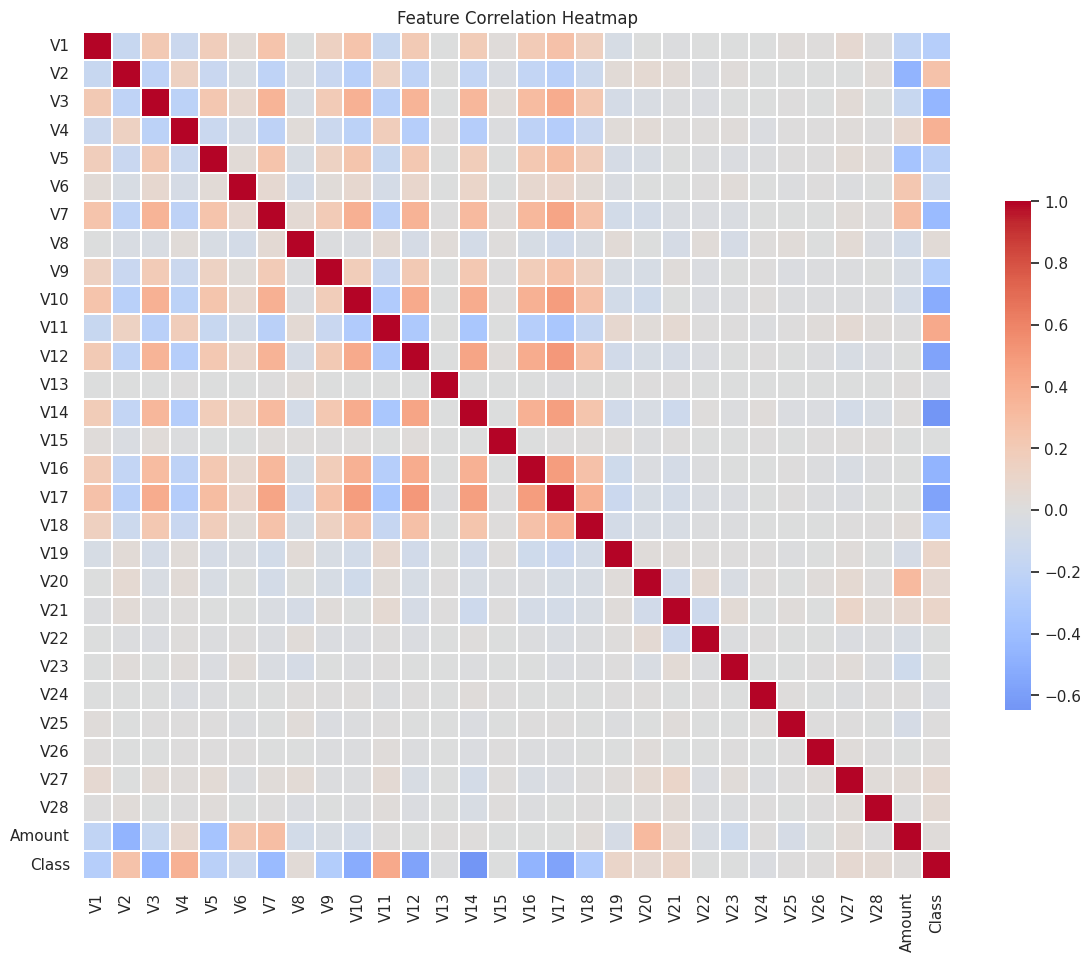

Top 8 features most correlated with Class:
V14   -0.646226
V17   -0.575181
V12   -0.569415
V10   -0.517501
V16   -0.469196
V3    -0.455432
V7    -0.423161
V11    0.415576
Name: Class, dtype: float64


In [7]:

# Correlation heatmap across all features
plt.figure(figsize=(14, 11))
corr = df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2, cbar_kws={"shrink": .6})
plt.title("Feature Correlation Heatmap")
plt.show()

# Which features correlate most strongly (in either direction) with Class?
corr_with_target = corr["Class"].drop("Class").sort_values(key=np.abs, ascending=False)
print("Top 8 features most correlated with Class:")
print(corr_with_target.head(8))


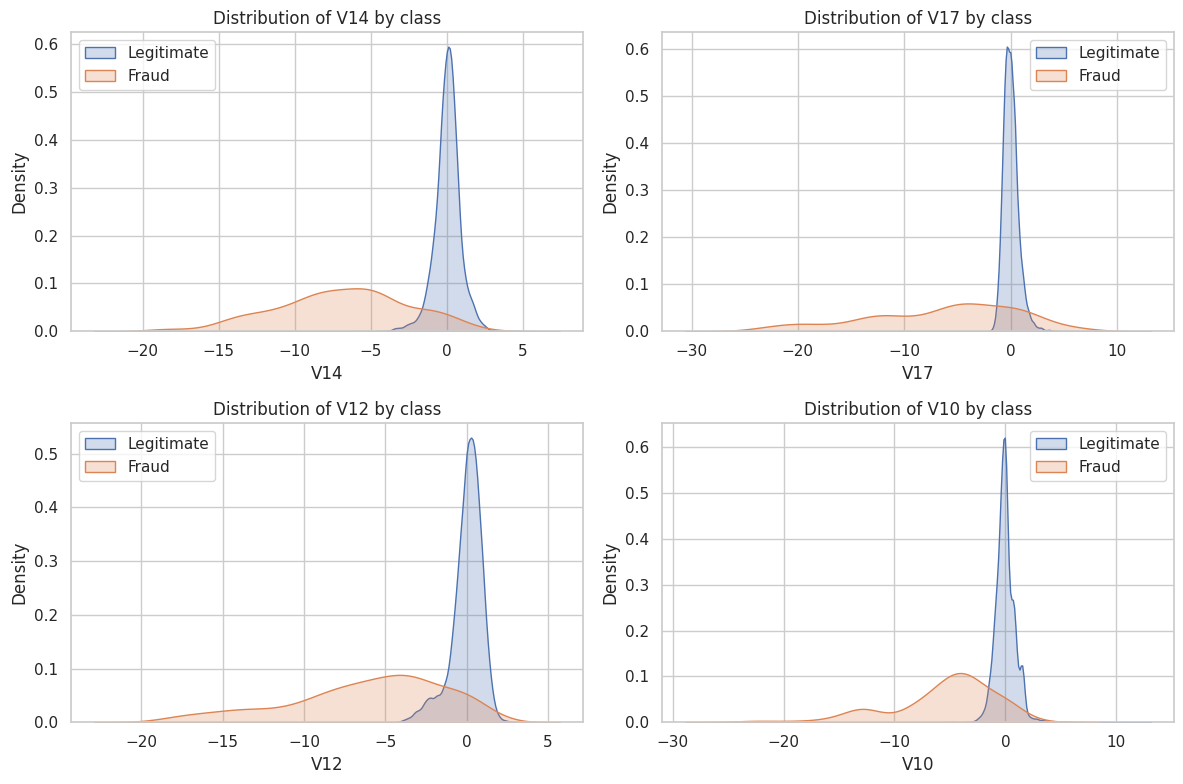

In [8]:

# Distribution of the most discriminative features, fraud vs legitimate
top_feats = corr_with_target.head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feat, ax in zip(top_feats, axes.ravel()):
    sns.kdeplot(df.loc[df.Class == 0, feat], label="Legitimate", ax=ax, fill=True)
    sns.kdeplot(df.loc[df.Class == 1, feat], label="Fraud", ax=ax, fill=True)
    ax.set_title(f"Distribution of {feat} by class")
    ax.legend()
plt.tight_layout()
plt.show()


## 3. Preprocessing

- Split into train/test **before** any resampling, using stratification to
  preserve the fraud ratio in both sets.
- Scale `Amount` (the `V*` features are already PCA components on a
  comparable scale).
- Apply **SMOTE** (Synthetic Minority Over-sampling) to the **training set
  only** — the test set must stay untouched and realistic.

In [9]:

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled["Amount"] = scaler.fit_transform(X_train[["Amount"]])
X_test_scaled["Amount"] = scaler.transform(X_test[["Amount"]])

print("Train shape:", X_train_scaled.shape, " Fraud rate:", y_train.mean().round(4))
print("Test shape: ", X_test_scaled.shape, " Fraud rate:", y_test.mean().round(4))


Train shape: (16269, 29)  Fraud rate: 0.0164
Test shape:  (5424, 29)  Fraud rate: 0.0164


Before SMOTE: {0: 16002, 1: 267}
After SMOTE:  {0: 16002, 1: 16002}


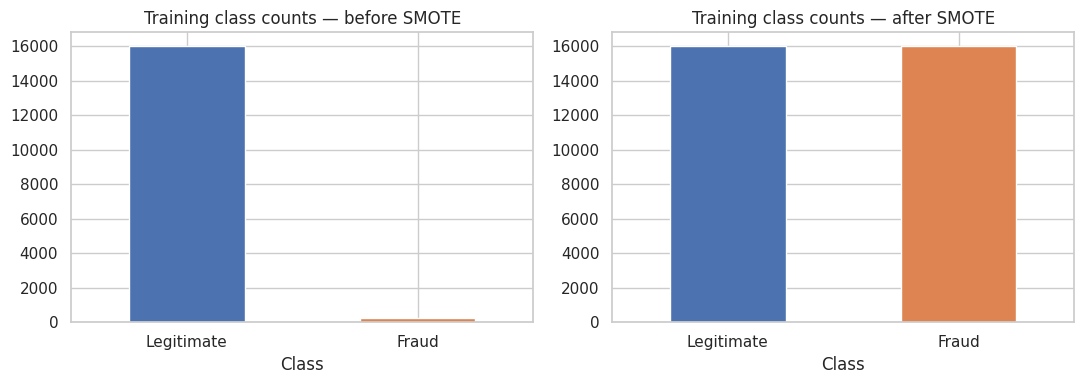

In [10]:

smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_res.value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
y_train.value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Training class counts — before SMOTE")
ax[0].set_xticklabels(["Legitimate", "Fraud"], rotation=0)
y_train_res.value_counts().sort_index().plot(kind="bar", ax=ax[1], color=["#4C72B0", "#DD8452"])
ax[1].set_title("Training class counts — after SMOTE")
ax[1].set_xticklabels(["Legitimate", "Fraud"], rotation=0)
plt.tight_layout()
plt.show()


## 4. Models

We train five models spanning classical ML, ensemble/boosting, unsupervised
anomaly detection, and deep learning. Predictions and probability scores are
stored in a shared dictionary so every model can be evaluated identically
later on.

In [11]:

results = {}   # results[model_name] = dict(y_pred=..., y_score=...)


### 4.1 Logistic Regression (classical ML baseline)

In [12]:

log_reg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_score = log_reg.predict_proba(X_test_scaled)[:, 1]
results["Logistic Regression"] = {"y_pred": y_pred, "y_score": y_score}
print("Logistic Regression trained.")


Logistic Regression trained.


### 4.2 Random Forest (trained on SMOTE-balanced data)

In [13]:

rf = RandomForestClassifier(
    n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1
)
rf.fit(X_train_res, y_train_res)

y_pred = rf.predict(X_test_scaled)
y_score = rf.predict_proba(X_test_scaled)[:, 1]
results["Random Forest"] = {"y_pred": y_pred, "y_score": y_score}
print("Random Forest trained.")


Random Forest trained.


### 4.3 XGBoost (gradient boosting)

In [14]:

xgb_clf = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
)
xgb_clf.fit(X_train_res, y_train_res)

y_pred = xgb_clf.predict(X_test_scaled)
y_score = xgb_clf.predict_proba(X_test_scaled)[:, 1]
results["XGBoost"] = {"y_pred": y_pred, "y_score": y_score}
print("XGBoost trained.")


XGBoost trained.


### 4.4 Isolation Forest (unsupervised "AI" anomaly detection)

Unlike the previous models, Isolation Forest never sees the labels during
training — it isolates points that are "few and different" in feature space.
This mirrors a real production scenario where confirmed fraud labels are
scarce or delayed.

In [15]:

fraud_rate_train = y_train.mean()

iso = IsolationForest(
    n_estimators=300, contamination=fraud_rate_train, random_state=RANDOM_STATE, n_jobs=-1
)
iso.fit(X_train_scaled)   # unsupervised: no y_train used

# -1 = anomaly (predicted fraud), 1 = normal -> remap to 1/0
raw_pred = iso.predict(X_test_scaled)
y_pred = np.where(raw_pred == -1, 1, 0)

# use the negative anomaly score as a continuous "fraud score" for ROC/PR curves
y_score = -iso.score_samples(X_test_scaled)
results["Isolation Forest"] = {"y_pred": y_pred, "y_score": y_score}
print("Isolation Forest trained (unsupervised).")


Isolation Forest trained (unsupervised).


### 4.5 Deep Learning — Supervised Feed-Forward Neural Network (Keras)

A compact multilayer perceptron trained on the SMOTE-balanced data with
dropout for regularization and early stopping on a validation split.

In [16]:

n_features = X_train_res.shape[1]

mlp = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

mlp.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(name="auc")])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=5, restore_best_weights=True
)

history = mlp.fit(
    X_train_res.values, y_train_res.values,
    validation_split=0.15,
    epochs=40,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0,
)
print(f"Training stopped after {len(history.history['loss'])} epochs.")


Training stopped after 6 epochs.


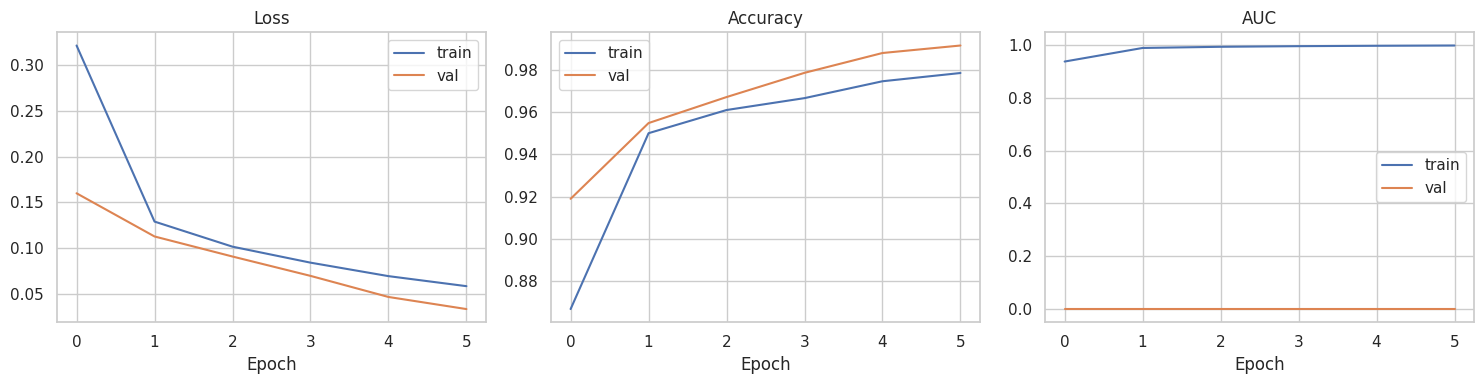

In [17]:

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()

ax[2].plot(history.history["auc"], label="train")
ax[2].plot(history.history["val_auc"], label="val")
ax[2].set_title("AUC"); ax[2].set_xlabel("Epoch"); ax[2].legend()
plt.tight_layout()
plt.show()


In [18]:

y_score = mlp.predict(X_test_scaled.values, verbose=0).ravel()
y_pred = (y_score >= 0.5).astype(int)
results["Deep Learning (MLP)"] = {"y_pred": y_pred, "y_score": y_score}
print("Deep learning MLP evaluated on test set.")


Deep learning MLP evaluated on test set.


### 4.6 Deep Learning — Unsupervised Autoencoder Anomaly Detector

The autoencoder is trained **only on legitimate transactions** to learn a
compressed representation of "normal" behavior. Fraudulent transactions,
never seen during training, should reconstruct poorly — the **reconstruction
error** becomes the anomaly score.

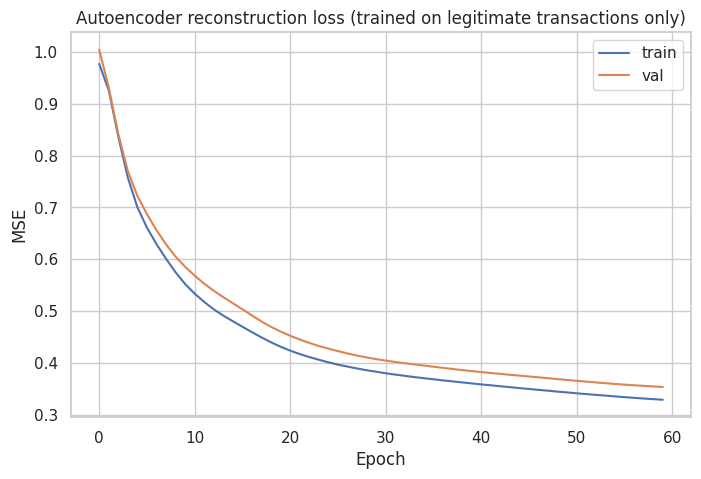

In [19]:

X_train_normal = X_train_scaled[y_train == 0].values

autoencoder = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(20, activation="relu"),
    layers.Dense(10, activation="relu"),
    layers.Dense(6, activation="relu"),   # bottleneck
    layers.Dense(10, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(n_features, activation="linear"),
])
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")

ae_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

ae_history = autoencoder.fit(
    X_train_normal, X_train_normal,
    validation_split=0.15,
    epochs=60,
    batch_size=256,
    callbacks=[ae_early_stop],
    verbose=0,
)

plt.plot(ae_history.history["loss"], label="train")
plt.plot(ae_history.history["val_loss"], label="val")
plt.title("Autoencoder reconstruction loss (trained on legitimate transactions only)")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend()
plt.show()


Reconstruction-error threshold (99th pct of normal training error): 1.7920


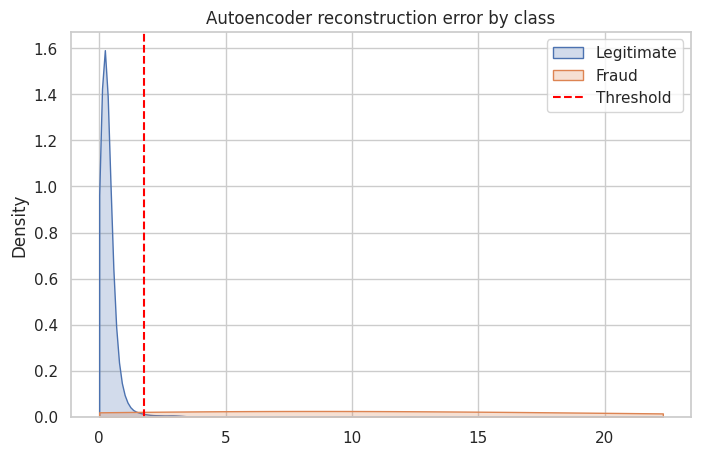

In [20]:

def reconstruction_error(model, X):
    X_pred = model.predict(X, verbose=0)
    return np.mean(np.square(X - X_pred), axis=1)

train_errors = reconstruction_error(autoencoder, X_train_normal)
test_errors = reconstruction_error(autoencoder, X_test_scaled.values)

# Threshold = 99th percentile of reconstruction error on known-legitimate training data
threshold = np.percentile(train_errors, 99)
print(f"Reconstruction-error threshold (99th pct of normal training error): {threshold:.4f}")

y_score = test_errors
y_pred = (test_errors > threshold).astype(int)
results["Deep Learning (Autoencoder)"] = {"y_pred": y_pred, "y_score": y_score}

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(test_errors[y_test.values == 0], label="Legitimate", fill=True, ax=ax, clip=(0, np.percentile(test_errors, 99.5)))
sns.kdeplot(test_errors[y_test.values == 1], label="Fraud", fill=True, ax=ax, clip=(0, np.percentile(test_errors, 99.5)))
ax.axvline(threshold, color="red", linestyle="--", label="Threshold")
ax.set_title("Autoencoder reconstruction error by class")
ax.legend()
plt.show()


## 5. Model Evaluation & Metrics

For imbalanced fraud detection, we report:
- **Accuracy** (context only — misleading alone)
- **Precision** — of all flagged transactions, how many are truly fraud?
- **Recall** — of all actual frauds, how many did we catch?
- **F1-score** — harmonic mean of precision & recall
- **ROC-AUC** — ranking quality across all thresholds
- **PR-AUC (Average Precision)** — the most informative metric here, since it
  focuses on performance on the rare positive (fraud) class

In [21]:

def evaluate(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "PR-AUC": average_precision_score(y_true, y_score),
    }

summary_rows = []
for name, r in results.items():
    row = evaluate(y_test, r["y_pred"], r["y_score"])
    row["Model"] = name
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
].sort_values("PR-AUC", ascending=False)

summary_df.style.background_gradient(cmap="Greens", subset=["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]).format("{:.4f}")


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.9967,0.9080,0.8876,0.8977,0.9927,0.9344
XGBoost,0.9958,0.8438,0.9101,0.8757,0.9865,0.9327
Deep Learning (MLP),0.9810,0.4615,0.9438,0.6199,0.9808,0.9079
Logistic Regression,0.9685,0.3360,0.9438,0.4956,0.9900,0.9031
Deep Learning (Autoencoder),0.9841,0.5096,0.8989,0.6504,0.9829,0.8108
Isolation Forest,0.9849,0.5315,0.6629,0.5900,0.9665,0.6139


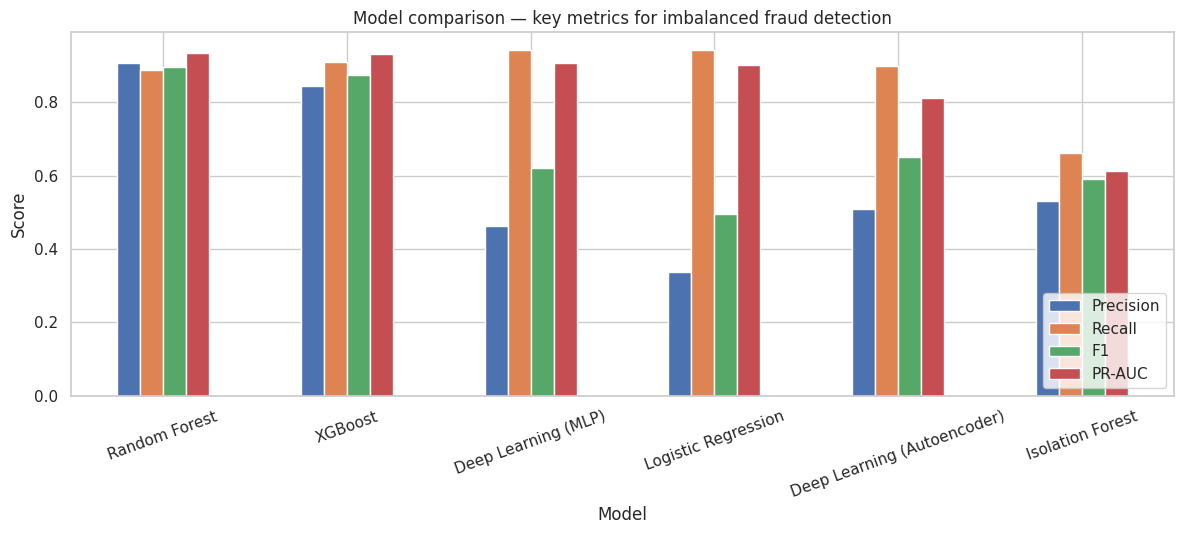

In [22]:

summary_df[["Precision", "Recall", "F1", "PR-AUC"]].plot(
    kind="bar", figsize=(12, 5.5), rot=20
)
plt.title("Model comparison — key metrics for imbalanced fraud detection")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


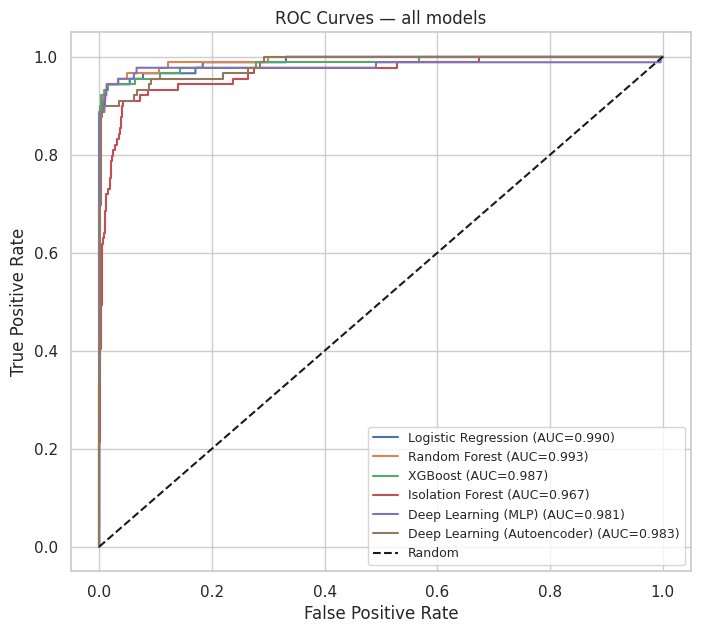

In [23]:

plt.figure(figsize=(8, 7))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_score"])
    auc = roc_auc_score(y_test, r["y_score"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — all models")
plt.legend(loc="lower right", fontsize=9)
plt.show()


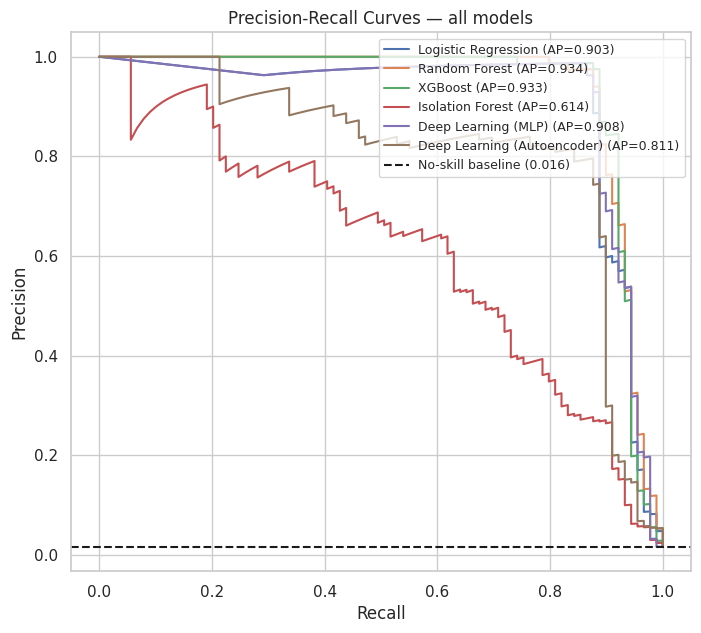

In [24]:

plt.figure(figsize=(8, 7))
baseline = y_test.mean()
for name, r in results.items():
    prec, rec, _ = precision_recall_curve(y_test, r["y_score"])
    ap = average_precision_score(y_test, r["y_score"])
    plt.plot(rec, prec, label=f"{name} (AP={ap:.3f})")
plt.axhline(baseline, color="k", linestyle="--", label=f"No-skill baseline ({baseline:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — all models")
plt.legend(loc="upper right", fontsize=9)
plt.show()


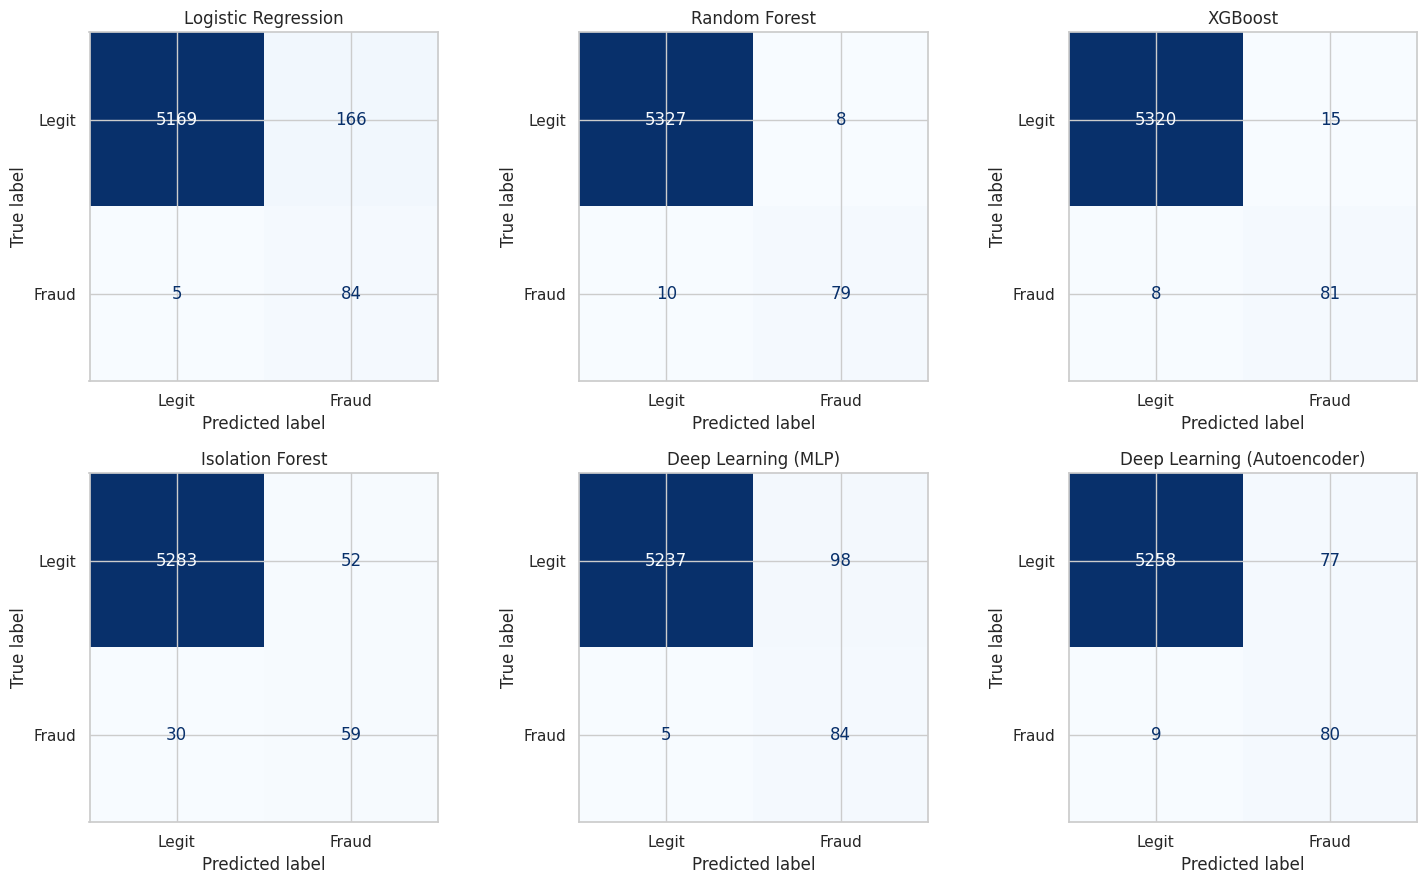

In [25]:

n_models = len(results)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    cm = confusion_matrix(y_test, r["y_pred"])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Legit", "Fraud"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
# hide any unused subplot
for ax in axes.ravel()[n_models:]:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [26]:

best_model_name = summary_df["PR-AUC"].idxmax()
print(f"Best model by PR-AUC: {best_model_name}\n")
print(classification_report(y_test, results[best_model_name]["y_pred"], target_names=["Legitimate", "Fraud"], digits=4))


Best model by PR-AUC: Random Forest

              precision    recall  f1-score   support

  Legitimate     0.9981    0.9985    0.9983      5335
       Fraud     0.9080    0.8876    0.8977        89

    accuracy                         0.9967      5424
   macro avg     0.9531    0.9431    0.9480      5424
weighted avg     0.9966    0.9967    0.9967      5424



## 6. Feature Importance

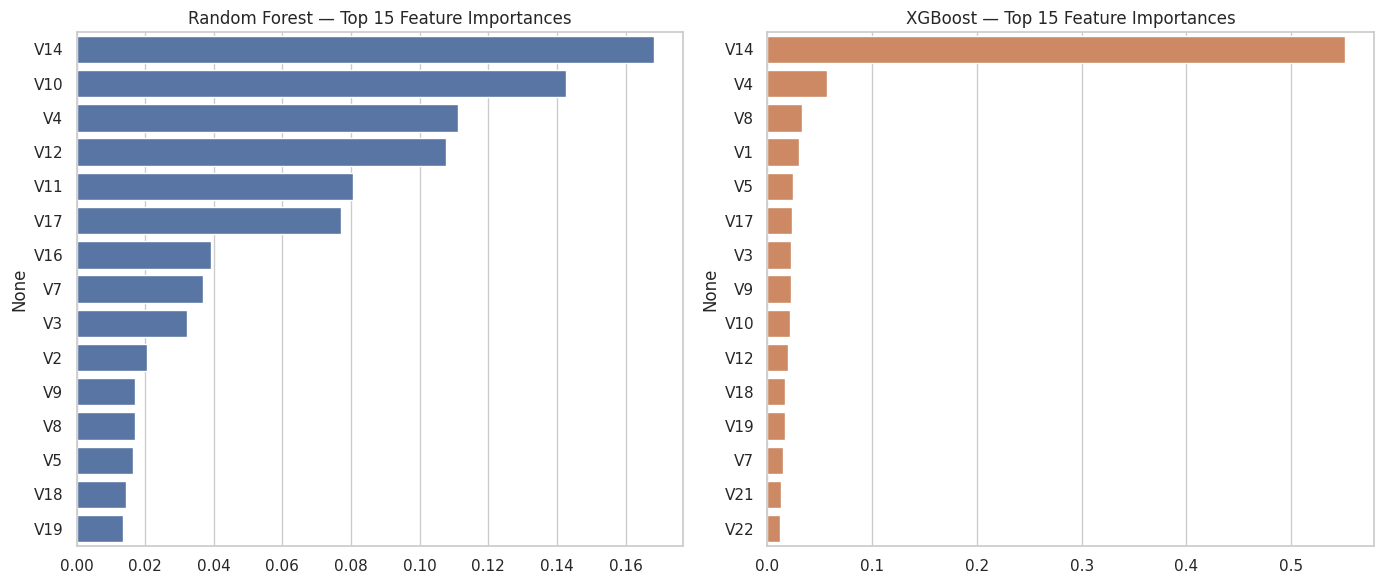

In [27]:

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

rf_importance = pd.Series(rf.feature_importances_, index=X_train_scaled.columns).sort_values(ascending=False).head(15)
sns.barplot(x=rf_importance.values, y=rf_importance.index, ax=ax[0], color="#4C72B0")
ax[0].set_title("Random Forest — Top 15 Feature Importances")

xgb_importance = pd.Series(xgb_clf.feature_importances_, index=X_train_scaled.columns).sort_values(ascending=False).head(15)
sns.barplot(x=xgb_importance.values, y=xgb_importance.index, ax=ax[1], color="#DD8452")
ax[1].set_title("XGBoost — Top 15 Feature Importances")

plt.tight_layout()
plt.show()


## 7. Decision-Threshold Tuning

Model scores are continuous; the 0.5 cutoff is arbitrary. In a real fraud
system there's a cost trade-off: a **false negative** (missed fraud) is
usually far more expensive than a **false positive** (a legitimate
transaction flagged for review). We scan thresholds on the best model's
score and choose the one maximizing F1 as an example — in production this
would instead be tuned against actual cost estimates.

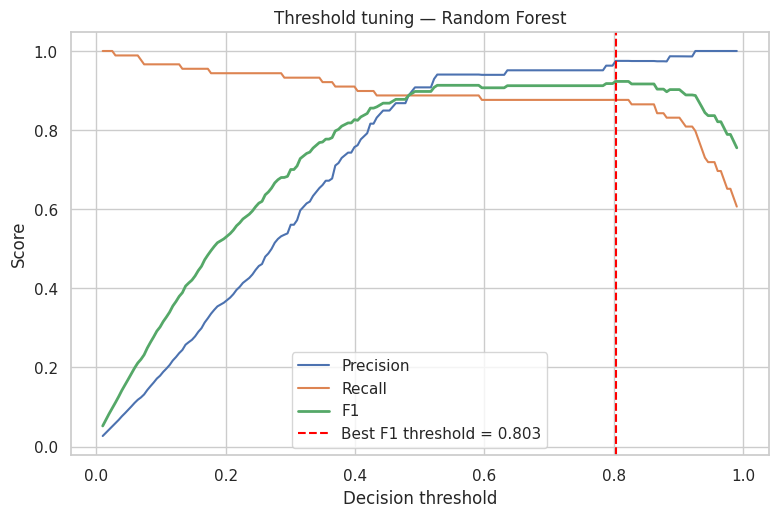

At threshold=0.803:
              precision    recall  f1-score   support

  Legitimate     0.9979    0.9996    0.9988      5335
       Fraud     0.9750    0.8764    0.9231        89

    accuracy                         0.9976      5424
   macro avg     0.9865    0.9380    0.9609      5424
weighted avg     0.9976    0.9976    0.9975      5424



In [28]:

best_scores = results[best_model_name]["y_score"]
thresholds = np.linspace(0.01, 0.99, 200) if best_scores.max() <= 1.0 else np.percentile(best_scores, np.linspace(1, 99, 200))

f1s, precisions, recalls = [], [], []
for t in thresholds:
    pred_t = (best_scores >= t).astype(int)
    f1s.append(f1_score(y_test, pred_t, zero_division=0))
    precisions.append(precision_score(y_test, pred_t, zero_division=0))
    recalls.append(recall_score(y_test, pred_t, zero_division=0))

best_idx = int(np.argmax(f1s))
best_threshold = thresholds[best_idx]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(thresholds, precisions, label="Precision")
ax.plot(thresholds, recalls, label="Recall")
ax.plot(thresholds, f1s, label="F1", linewidth=2)
ax.axvline(best_threshold, color="red", linestyle="--", label=f"Best F1 threshold = {best_threshold:.3f}")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title(f"Threshold tuning — {best_model_name}")
ax.legend()
plt.show()

final_pred = (best_scores >= best_threshold).astype(int)
print(f"At threshold={best_threshold:.3f}:")
print(classification_report(y_test, final_pred, target_names=["Legitimate", "Fraud"], digits=4))


## 8. Conclusions & Next Steps

**Findings**
- Fraud detection is fundamentally an **imbalanced classification** problem
  — accuracy is a poor metric; **PR-AUC, recall, and F1** are far more
  informative.
- Ensemble/boosted tree models (Random Forest, XGBoost) trained on
  SMOTE-balanced data typically achieve strong precision-recall trade-offs
  on this kind of tabular, PCA-transformed data.
- The **supervised deep-learning MLP** is competitive with tree ensembles
  but is more sensitive to preprocessing and architecture/hyperparameter
  choices.
- The **unsupervised methods** (Isolation Forest, autoencoder) don't need
  fraud labels at training time — valuable when labels are scarce, delayed,
  or you want to catch entirely new fraud patterns — but they generally
  trade some precision/recall for that label-free flexibility.
- Threshold tuning matters: the "right" operating point depends on the
  relative cost of missed fraud vs. false alarms, which should come from
  the business, not a default 0.5 cutoff.

**Possible extensions**
- Cost-sensitive learning with explicit false-negative/false-positive costs
- Hyperparameter tuning (grid/Bayesian search) for each model
- Cross-validation instead of a single train/test split, for more robust
  estimates
- Model explainability (e.g., SHAP values) for individual flagged transactions
- Ensembling / stacking multiple models
- Streaming/online learning for real-time transaction scoring
- Testing on the full 284,807-row original dataset for higher statistical
  power

**References**
- Dataset: ULB Machine Learning Group / Worldline — Credit Card Fraud
  Detection (subset via University of Michigan's "Applied Machine Learning
  in Python" course materials)
- Chawla et al., "SMOTE: Synthetic Minority Over-sampling Technique" (2002)
- Liu, Ting & Zhou, "Isolation Forest" (2008)
